# 02 · BPE From Scratch

> **The showpiece.** Byte-pair encoding in ~50 lines: start from raw bytes,
> count every adjacent pair, merge the most frequent pair into a new token,
> record the rule, repeat. Watch common chunks — `the`, `ing`, a space plus a
> common word — crystallize into single tokens.

In [1]:
import os
import sys
import pathlib

_p = pathlib.Path.cwd()
while not (_p / "pyproject.toml").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p)
if str(_p) not in sys.path:
    sys.path.insert(0, str(_p))

import json

import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11

from src.artifacts import save_figure, save_json

print("repo root:", _p)

repo root: /workspaces/tokenization_101


## One step of the algorithm, by hand

In [2]:
from src.bpe.train import best_pair, get_stats, merge

ids = list("aaabdaaabac".encode("utf-8"))
print("ids:", ids)

stats = get_stats(ids)
print("pair counts:", dict(stats))

pair = best_pair(stats)
print("most frequent pair:", pair, "count", stats[pair])
print("after merging that pair -> new token 256:", merge(ids, pair, 256))

ids: [97, 97, 97, 98, 100, 97, 97, 97, 98, 97, 99]
pair counts: {(97, 97): 4, (97, 98): 2, (98, 100): 1, (100, 97): 1, (98, 97): 1, (97, 99): 1}
most frequent pair: (97, 97) count 4
after merging that pair -> new token 256: [256, 97, 98, 100, 256, 97, 98, 97, 99]


## Train on a real corpus

In [3]:
from src.bpe import BPETokenizer
from src.datasets.corpora import training_corpus

corpus = training_corpus(60_000)
tok = BPETokenizer().train(corpus, vocab_size=512)
print(f"corpus chars : {len(corpus)}")
print(f"vocab size   : {tok.vocab_size}")
print(f"merges learned: {len(tok.merges)}")

corpus chars : 60000
vocab size   : 512
merges learned: 256


## Watch the chunks crystallize

In [4]:
table = tok.merge_table()
for row in table[:40]:
    print(f"{row.rank:>3}  {str(row.pair):>12}  ->  {row.new_id:>4}   {row.piece!r}")

print(
    "saved:",
    save_json(
        "02_merges",
        [
            {"rank": r.rank, "pair": list(r.pair), "new_id": r.new_id, "piece": r.piece}
            for r in table
        ],
    ),
)

  0     (101, 32)  ->   256   'e·'
  1     (32, 116)  ->   257   '·t'
  2      (32, 97)  ->   258   '·a'
  3    (257, 104)  ->   259   '·th'
  4    (105, 110)  ->   260   'in'
  5     (115, 32)  ->   261   's·'
  6     (116, 32)  ->   262   't·'
  7    (101, 114)  ->   263   'er'
  8    (110, 100)  ->   264   'nd'
  9    (259, 256)  ->   265   '·the·'
 10    (111, 114)  ->   266   'or'
 11     (97, 114)  ->   267   'ar'
 12    (101, 110)  ->   268   'en'
 13     (32, 115)  ->   269   '·s'
 14    (111, 117)  ->   270   'ou'
 15    (260, 103)  ->   271   'ing'
 16    (111, 110)  ->   272   'on'
 17     (32, 119)  ->   273   '·w'
 18    (258, 264)  ->   274   '·and'
 19     (97, 110)  ->   275   'an'
 20    (116, 104)  ->   276   'th'
 21      (46, 32)  ->   277   '.·'
 22      (32, 99)  ->   278   '·c'
 23    (114, 101)  ->   279   're'
 24    (108, 101)  ->   280   'le'
 25    (257, 111)  ->   281   '·to'
 26    (115, 258)  ->   282   's·a'
 27    (111, 102)  ->   283   'of'
 28     (44

Early merges are natural sub-word chunks; as merging continues, tokens grow from single bytes into longer pieces.

saved: /workspaces/tokenization_101/outputs/figures/02_merge_growth.png


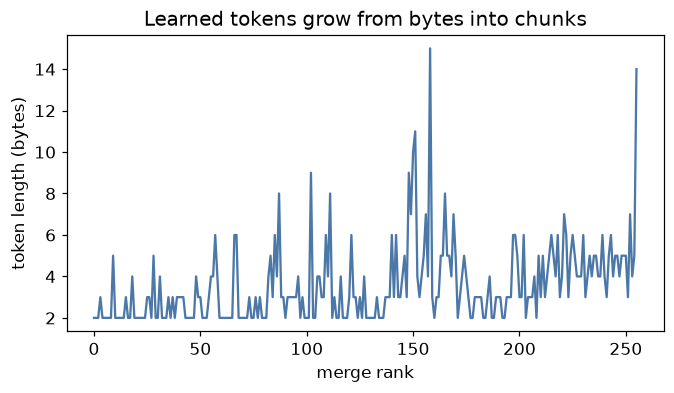

In [5]:
ranks = [r.rank for r in table]
lengths = [len(tok.vocab[r.new_id]) for r in table]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(ranks, lengths, color="#4C78A8")
ax.set_xlabel("merge rank")
ax.set_ylabel("token length (bytes)")
ax.set_title("Learned tokens grow from bytes into chunks")
print("saved:", save_figure(fig, "02_merge_growth"))
plt.show()

## Encode, decode, and a tested round-trip

In [6]:
sample = "the model reads tokens, not letters"
ids = tok.encode(sample)
pieces = tok.pieces(sample)
restored = tok.decode(ids)

print("tokens :", pieces)
print("ids    :", ids)
print("decoded:", restored)
print("round-trip ok:", restored == sample)
assert restored == sample

print(
    "saved:",
    save_json(
        "02_roundtrip",
        {
            "text": sample,
            "token_ids": ids,
            "pieces": pieces,
            "decoded": restored,
            "roundtrip_ok": restored == sample,
        },
    ),
)

tokens : ['th', 'e ', 'model', ' ', 'read', 's', ' token', 's, ', 'not ', 'letter', 's']
ids    : [276, 256, 510, 32, 312, 115, 313, 456, 314, 341, 115]
decoded: the model reads tokens, not letters
round-trip ok: True
saved: /workspaces/tokenization_101/outputs/data/02_roundtrip.json


saved: /workspaces/tokenization_101/outputs/figures/02_token_breakdown.png


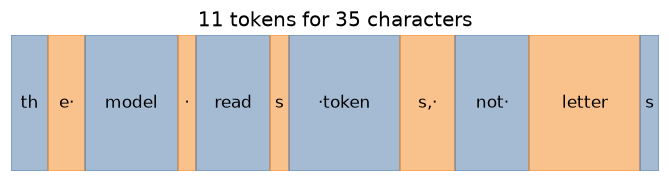

In [7]:
from src.visualisation import plot_token_breakdown

fig = plot_token_breakdown(tok, sample)
print("saved:", save_figure(fig, "02_token_breakdown"))
plt.show()

## Validate against a production tokenizer

In [8]:
from src.reference.compare import try_get_reference_encoding

enc = try_get_reference_encoding("gpt2")
check = {"reference_available": enc is not None}
if enc is not None:
    text = "tokenization is compression"
    check.update(
        {
            "text": text,
            "ours_roundtrip_ok": tok.decode(tok.encode(text)) == text,
            "reference_roundtrip_ok": enc.decode(enc.encode(text)) == text,
            "ours_tokens": len(tok.encode(text)),
            "reference_tokens": len(enc.encode(text)),
        }
    )
    print(check)
else:
    print("tiktoken unavailable (offline) - skipping reference comparison")

print("saved:", save_json("02_reference_check", check))

{'reference_available': True, 'text': 'tokenization is compression', 'ours_roundtrip_ok': True, 'reference_roundtrip_ok': True, 'ours_tokens': 13, 'reference_tokens': 4}
saved: /workspaces/tokenization_101/outputs/data/02_reference_check.json


**Takeaway.** This is the real algorithm behind GPT's tokenizer. It is a
*reversible compression* learned from frequency — not a designed dictionary and
not a lossy mystery. Everything that follows is a consequence of what it merged.